## Movie review classification


In [ ]:
from keras.datasets import imdb

In [9]:
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(
    num_words=10000
)

In [10]:
train_data.shape

(25000,)

In [11]:
train_labels.shape

(25000,)

In [13]:
train_data[0]

[1,
 14,
 22,
 16,
 43,
 530,
 973,
 1622,
 1385,
 65,
 458,
 4468,
 66,
 3941,
 4,
 173,
 36,
 256,
 5,
 25,
 100,
 43,
 838,
 112,
 50,
 670,
 2,
 9,
 35,
 480,
 284,
 5,
 150,
 4,
 172,
 112,
 167,
 2,
 336,
 385,
 39,
 4,
 172,
 4536,
 1111,
 17,
 546,
 38,
 13,
 447,
 4,
 192,
 50,
 16,
 6,
 147,
 2025,
 19,
 14,
 22,
 4,
 1920,
 4613,
 469,
 4,
 22,
 71,
 87,
 12,
 16,
 43,
 530,
 38,
 76,
 15,
 13,
 1247,
 4,
 22,
 17,
 515,
 17,
 12,
 16,
 626,
 18,
 2,
 5,
 62,
 386,
 12,
 8,
 316,
 8,
 106,
 5,
 4,
 2223,
 5244,
 16,
 480,
 66,
 3785,
 33,
 4,
 130,
 12,
 16,
 38,
 619,
 5,
 25,
 124,
 51,
 36,
 135,
 48,
 25,
 1415,
 33,
 6,
 22,
 12,
 215,
 28,
 77,
 52,
 5,
 14,
 407,
 16,
 82,
 2,
 8,
 4,
 107,
 117,
 5952,
 15,
 256,
 4,
 2,
 7,
 3766,
 5,
 723,
 36,
 71,
 43,
 530,
 476,
 26,
 400,
 317,
 46,
 7,
 4,
 2,
 1029,
 13,
 104,
 88,
 4,
 381,
 15,
 297,
 98,
 32,
 2071,
 56,
 26,
 141,
 6,
 194,
 7486,
 18,
 4,
 226,
 22,
 21,
 134,
 476,
 26,
 480,
 5,
 144,
 30,
 5535,
 18,

In [7]:
train_labels[0]

np.int64(1)

In [12]:
max([max(sequence) for sequence in train_data])

9999

In [14]:
word_index = imdb.get_word_index()

reverse_word_index = dict([(val, key) for (key, val) in word_index.items()])


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [18]:
reverse_word_index

{34701: 'fawn',
 52006: 'tsukino',
 52007: 'nunnery',
 16816: 'sonja',
 63951: 'vani',
 1408: 'woods',
 16115: 'spiders',
 2345: 'hanging',
 2289: 'woody',
 52008: 'trawling',
 52009: "hold's",
 11307: 'comically',
 40830: 'localized',
 30568: 'disobeying',
 52010: "'royale",
 40831: "harpo's",
 52011: 'canet',
 19313: 'aileen',
 52012: 'acurately',
 52013: "diplomat's",
 25242: 'rickman',
 6746: 'arranged',
 52014: 'rumbustious',
 52015: 'familiarness',
 52016: "spider'",
 68804: 'hahahah',
 52017: "wood'",
 40833: 'transvestism',
 34702: "hangin'",
 2338: 'bringing',
 40834: 'seamier',
 34703: 'wooded',
 52018: 'bravora',
 16817: 'grueling',
 1636: 'wooden',
 16818: 'wednesday',
 52019: "'prix",
 34704: 'altagracia',
 52020: 'circuitry',
 11585: 'crotch',
 57766: 'busybody',
 52021: "tart'n'tangy",
 14129: 'burgade',
 52023: 'thrace',
 11038: "tom's",
 52025: 'snuggles',
 29114: 'francesco',
 52027: 'complainers',
 52125: 'templarios',
 40835: '272',
 52028: '273',
 52130: 'zaniacs',

In [19]:
decoded_review = " ".join(
    [reverse_word_index.get(i - 3, "?") for i in train_data[0]]
)

In [22]:
decoded_review[:200]

"? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the sa"

In [23]:
max([len(data) for data in train_data])

2494

In [24]:
min([len(data) for data in train_data])

11

### Data preprocessing

In [25]:
import numpy as np

def multi_hot_encode(sequences, num_classes):
    # Creates an all-zero matrix of shape( len(sequence), num_classes)
    results = np.zeros((len(sequences), num_classes))

    for i, sequence in enumerate(sequences):
        results[i][sequence] = 1.0

    return results

x_train = multi_hot_encode(train_data, num_classes=10000)

x_test = multi_hot_encode(test_data, num_classes=10000)


In [26]:
x_train[0]

array([0., 1., 1., ..., 0., 0., 0.], shape=(10000,))

In [27]:
y_train = train_labels.astype("float32")
y_test = test_labels.astype("float32")

### Building the model

In [28]:
import keras
from keras import layers

model = keras.Sequential(
    [
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ]
)

In [29]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [31]:
x_val = x_train[:10000]
x_train_partial = x_train[10000:]

y_val = y_train[:10000]
y_train_partial = y_train[10000:]

In [32]:
history = model.fit(
    x_train_partial,
    y_train_partial,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val),
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 116ms/step - accuracy: 0.7487 - loss: 0.5749 - val_accuracy: 0.8534 - val_loss: 0.4484
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8925 - loss: 0.3501 - val_accuracy: 0.8837 - val_loss: 0.3279
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9231 - loss: 0.2414 - val_accuracy: 0.8921 - val_loss: 0.2863
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9433 - loss: 0.1816 - val_accuracy: 0.8896 - val_loss: 0.2761
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.9591 - loss: 0.1413 - val_accuracy: 0.8867 - val_loss: 0.2811
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9695 - loss: 0.1122 - val_accuracy: 0.8851 - val_loss: 0.2933
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.9781 - loss: 0.0898 - val_accuracy: 0.8834 - val_loss: 0.3095
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9861 - loss: 0.0712 - val_accuracy: 0.8806 - 

In [33]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [35]:
print(history_dict["accuracy"])
print(history_dict["loss"])
print(history_dict["val_accuracy"])
print(history_dict["val_loss"])

[0.7486666440963745, 0.8925333619117737, 0.9230666756629944, 0.9432666897773743, 0.9590666890144348, 0.9695333242416382, 0.9781333208084106, 0.9860666394233704, 0.9897333383560181, 0.9932000041007996, 0.9955999851226807, 0.9973333477973938, 0.9986666440963745, 0.9991999864578247, 0.9995999932289124, 0.9997333288192749, 0.9999333620071411, 0.9999333620071411, 0.9999333620071411, 0.9999333620071411]
[0.574862003326416, 0.35007110238075256, 0.241398885846138, 0.18157219886779785, 0.14133520424365997, 0.11216896772384644, 0.08982258290052414, 0.07116163522005081, 0.056818053126335144, 0.04509522393345833, 0.03579248487949371, 0.028358185663819313, 0.022575154900550842, 0.018183358013629913, 0.0148181626573205, 0.012035604566335678, 0.009969131089746952, 0.008519400842487812, 0.0071743144653737545, 0.0061577861197292805]
[0.8533999919891357, 0.8837000131607056, 0.8920999765396118, 0.8895999789237976, 0.8866999745368958, 0.8851000070571899, 0.883400022983551, 0.8805999755859375, 0.8795999884

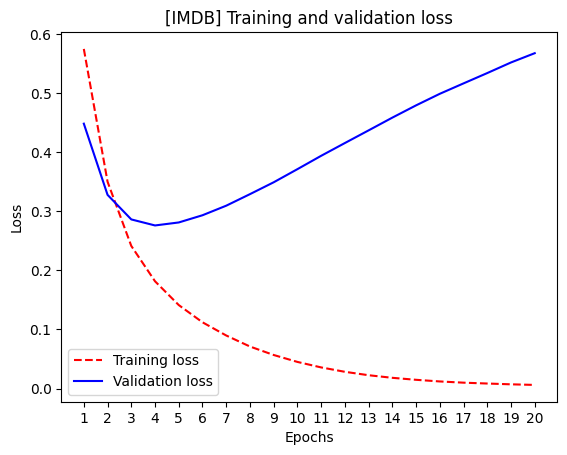

In [36]:
import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
# "r--" is for "dashed red line."
plt.plot(epochs, loss_values, "r--", label="Training loss")
# "b" is for "solid blue line."
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("[IMDB] Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

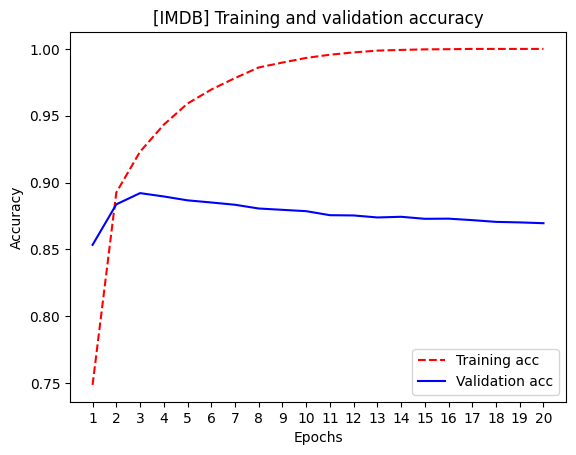

In [37]:
# Clears the figure
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("[IMDB] Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [40]:
model = keras.Sequential(
    [
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ]
)

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.fit(x_train, y_train, epochs=4, batch_size=512)
results = model.evaluate(x_test, y_test)

Epoch 1/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.7947 - loss: 0.5174
Epoch 2/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9025 - loss: 0.2816
Epoch 3/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.9268 - loss: 0.2052
Epoch 4/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.9430 - loss: 0.1632
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8843 - loss: 0.2926


In [41]:
results

[0.29258278012275696, 0.8842800259590149]

In [42]:
model.predict(x_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


array([[0.21383213],
       [0.99980766],
       [0.88591886],
       ...,
       [0.11283267],
       [0.09195267],
       [0.6340823 ]], shape=(25000, 1), dtype=float32)

## Multiclass classification

In [43]:
from keras.datasets import reuters

(train_data, train_labels), (test_data, test_lables) = reuters.load_data(
    num_words=10000
)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [49]:
print(len(train_data))
print(len(test_data))

8982
2246


In [46]:
train_data.shape

(8982,)

In [48]:
print(train_labels.shape)
print(train_labels[0])

(8982,)
3


In [50]:
word_index = reuters.get_word_index()
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])
decoded_newswire = " ".join(
    # The indices are offset by 3 because 0, 1, and 2 are reserved
    # indices for "padding," "start of sequence," and "unknown."
    [reverse_word_index.get(i - 3, "?") for i in train_data[10]]
)

550378/550378 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [51]:
decoded_newswire

'? period ended december 31 shr profit 11 cts vs loss 24 cts net profit 224 271 vs loss 511 349 revs 7 258 688 vs 7 200 349 reuter 3'

### Preparing the data

In [52]:
x_train = multi_hot_encode(train_data, num_classes=10000)
x_test = multi_hot_encode(test_data, num_classes=10000)

In [53]:
def one_hot_encode(labels, num_classes=46):
    results = np.zeros((len(labels), num_classes))

    for i, label in enumerate(labels):
        results[i][label] = 1.0
    return results

y_train = one_hot_encode(train_labels)
y_test = one_hot_encode(test_lables)


In [54]:
y_train[0]

array([0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

### Building the model

In [55]:
model = keras.Sequential(
    [
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(46, activation="softmax"),
    ]
)

In [58]:
top_3_accuracy = keras.metrics.TopKCategoricalAccuracy(
    k=3, name="top_3_accuracy"
)
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy", top_3_accuracy],
)

In [56]:
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = y_train[:1000]
partial_y_train = y_train[1000:]

In [59]:
history = model.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val),
)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.3869 - loss: 3.4371 - top_3_accuracy: 0.5132 - val_accuracy: 0.5220 - val_loss: 2.7353 - val_top_3_accuracy: 0.6930
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.5879 - loss: 2.1530 - top_3_accuracy: 0.7439 - val_accuracy: 0.6410 - val_loss: 1.7184 - val_top_3_accuracy: 0.7620
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - accuracy: 0.7081 - loss: 1.4045 - top_3_accuracy: 0.7960 - val_accuracy: 0.6970 - val_loss: 1.3266 - val_top_3_accuracy: 0.8140
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.7652 - loss: 1.0689 - top_3_accuracy: 0.8517 - val_accuracy: 0.7390 - val_loss: 1.1643 - val_top_3_accuracy: 0.8390
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.8181 - loss: 0.8540 - top_3_accuracy: 0.8958 - val_accuracy: 0.7770 - val_loss: 1.0701 - val_top_3_accuracy: 0.8680
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8589 - loss: 0.6805 - top_3_a

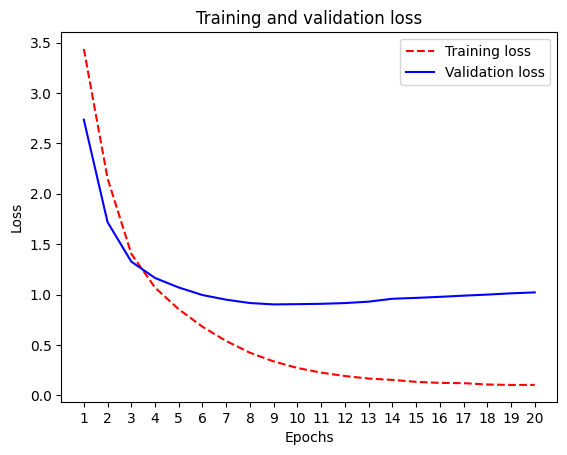

In [60]:
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, "r--", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

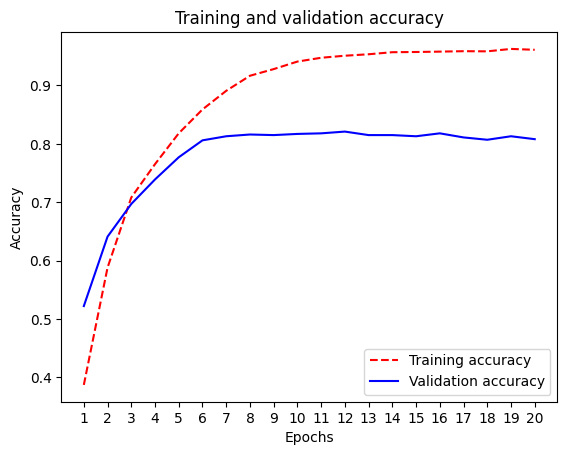

In [61]:
plt.clf()
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

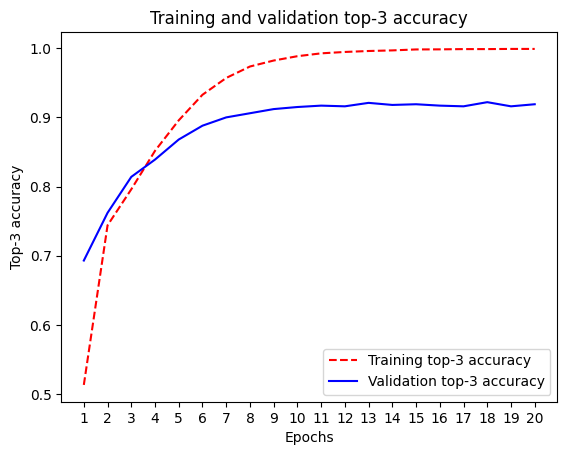

In [62]:
plt.clf()
acc = history.history["top_3_accuracy"]
val_acc = history.history["val_top_3_accuracy"]
plt.plot(epochs, acc, "r--", label="Training top-3 accuracy")
plt.plot(epochs, val_acc, "b", label="Validation top-3 accuracy")
plt.title("Training and validation top-3 accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Top-3 accuracy")
plt.legend()
plt.show()

In [63]:
model = keras.Sequential(
    [
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(46, activation="softmax"),
    ]
)
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.fit(
    x_train,
    y_train,
    epochs=9,
    batch_size=512,
)
results = model.evaluate(x_test, y_test)

Epoch 1/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.4717 - loss: 3.1057
Epoch 2/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.6355 - loss: 1.7418
Epoch 3/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.7358 - loss: 1.2173
Epoch 4/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - accuracy: 0.8016 - loss: 0.9385
Epoch 5/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 0.8473 - loss: 0.7303
Epoch 6/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.8828 - loss: 0.5667
Epoch 7/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.9075 - loss: 0.4425
Epoch 8/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9265 - loss: 0.3501
Epoch 9/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9379 - loss: 0.2806
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7939 - loss: 0.9395


In [64]:
results

[0.939477801322937, 0.7938557267189026]

In [65]:
predictions = model.predict(x_test)

71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


In [68]:
print(predictions[0])
np.sum(predictions[0])

[3.78277873e-05 6.76683383e-04 5.89884548e-05 8.48709881e-01
 1.16074957e-01 3.78988479e-05 8.26364849e-05 1.13722090e-04
 1.30510842e-02 2.69351323e-04 1.36271308e-04 2.04616529e-03
 2.94627680e-04 6.50041155e-04 4.60171650e-05 1.23544442e-05
 2.00482598e-03 6.57561293e-04 2.39431247e-04 2.53154663e-03
 4.62688785e-03 7.06062303e-04 1.69024162e-04 8.23967392e-04
 4.28841668e-05 1.26704981e-03 1.71732256e-06 1.15867995e-04
 1.00473539e-04 1.14184928e-04 1.69703120e-03 4.65700141e-04
 9.75912371e-06 2.13656076e-05 3.51963499e-05 2.44288130e-05
 3.36544530e-04 8.64994436e-05 9.45239808e-05 9.39344754e-05
 1.66140544e-05 6.78544457e-05 1.84959747e-04 1.13582157e-03
 1.35650271e-05 1.62326105e-05]


np.float32(1.0)

In [67]:
np.argmax(predictions[0])

np.int64(3)

## House pricing (Regression)

In [69]:
from keras.datasets import california_housing

# Make sure to pass version="small" to get the right dataset.
(train_data, train_targets), (test_data, test_targets) = (
    california_housing.load_data(version="small")
)

743530/743530 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [70]:
train_data.shape

(480, 8)

In [71]:
train_data[0]

array([-1.2224e+02,  3.7730e+01,  2.1000e+01,  7.0310e+03,  1.2490e+03,
        2.9300e+03,  1.2350e+03,  4.5213e+00], dtype=float32)

In [73]:
train_targets

array([228400., 132900.,  60000.,  95200., 107000., 122500., 132000.,
       290100., 257800., 390100., 220800., 284900.,  97500., 415300.,
        84200., 185600., 216700., 233100., 127000., 182300.,  92300.,
        90700., 102100., 112500., 350700., 156500., 220700., 147400.,
       216700., 275000., 198200., 119100., 289500., 152500., 125000.,
       104500.,  93800.,  89300., 452600., 128600., 311500.,  90000.,
       218200., 131300.,  67500., 139400., 500001., 182600., 111300.,
       112500., 134700.,  71300., 207400., 331400., 107900.,  87500.,
       342200.,  87100., 314700., 368600., 211600., 338900., 366100.,
       164300.,  91700., 261400., 218500., 155400., 273700.,  81800.,
       138800.,  99700., 156300., 140600., 152700., 108900., 351200.,
       126000., 137500., 196900., 240000., 172800., 254200.,  97500.,
       182700., 162500.,  86100., 226700., 412500., 165900., 327100.,
       162500., 188800., 183800.,  90600., 372000., 275000., 151800.,
       125000., 1291

### Preparing data

In [74]:
mean = train_data.mean(axis=0)
std = train_data.std(axis=0)

x_train = (train_data - mean) / std
x_test = (test_data - mean) / std

In [75]:
x_train[0]

array([-0.1761497, -1.5940031, -2.4240775,  3.4239438,  2.5898013,
        2.9189088,  2.8009396,  0.5019599], dtype=float32)

In [81]:
y_train = train_targets / 100000
y_test = test_targets / 100000

In [82]:
def get_model():
    # Because you need to instantiate the same model multiple times,
    # you use a function to construct it.
    model = keras.Sequential(
        [
            layers.Dense(64, activation="relu"),
            layers.Dense(64, activation="relu"),
            layers.Dense(1),
        ]
    )
    model.compile(
        optimizer="adam",
        loss="mean_squared_error",
        metrics=["mean_absolute_error"],
    )
    return model

In [83]:
k = 4
num_val_samples = len(x_train) // k
num_epochs = 50
all_scores = []
for i in range(k):
    print(f"Processing fold #{i + 1}")
    # Prepares the validation data: data from partition #k
    fold_x_val = x_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_y_val = y_train[i * num_val_samples : (i + 1) * num_val_samples]
    # Prepares the training data: data from all other partitions
    fold_x_train = np.concatenate(
        [x_train[: i * num_val_samples], x_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    fold_y_train = np.concatenate(
        [y_train[: i * num_val_samples], y_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    # Builds the Keras model (already compiled)
    model = get_model()
    # Trains the model
    model.fit(
        fold_x_train,
        fold_y_train,
        epochs=num_epochs,
        batch_size=16,
        verbose=0,
    )
    # Evaluates the model on the validation data
    scores = model.evaluate(fold_x_val, fold_y_val, verbose=0)
    val_loss, val_mae = scores
    all_scores.append(val_mae)

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


In [84]:
[round(value, 3) for value in all_scores]

[0.299, 0.273, 0.251, 0.336]

In [85]:
round(np.mean(all_scores), 3)

np.float64(0.29)

In [86]:
k = 4
num_val_samples = len(x_train) // k
num_epochs = 200
all_mae_histories = []
for i in range(k):
    print(f"Processing fold #{i + 1}")
    # Prepares the validation data: data from partition #k
    fold_x_val = x_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_y_val = y_train[i * num_val_samples : (i + 1) * num_val_samples]
    # Prepares the training data: data from all other partitions
    fold_x_train = np.concatenate(
        [x_train[: i * num_val_samples], x_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    fold_y_train = np.concatenate(
        [y_train[: i * num_val_samples], y_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    # Builds the Keras model (already compiled)
    model = get_model()
    # Trains the model
    history = model.fit(
        fold_x_train,
        fold_y_train,
        validation_data=(fold_x_val, fold_y_val),
        epochs=num_epochs,
        batch_size=16,
        verbose=0,
    )
    mae_history = history.history["val_mean_absolute_error"]
    all_mae_histories.append(mae_history)

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


In [87]:
average_mae_history = [
    np.mean([x[i] for x in all_mae_histories]) for i in range(num_epochs)
]

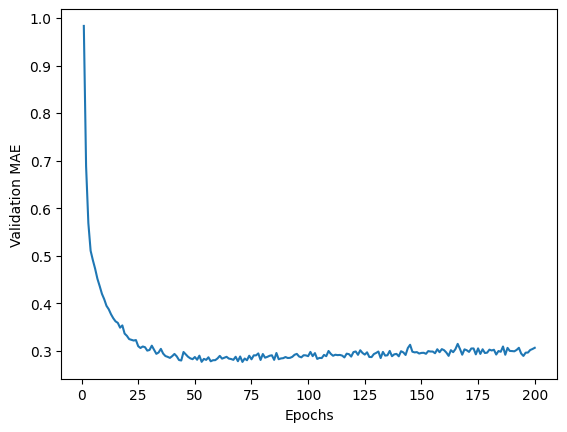

In [88]:
epochs = range(1, len(average_mae_history) + 1)
plt.plot(epochs, average_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

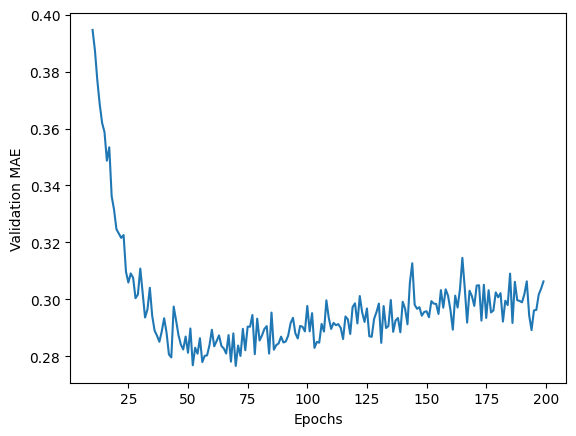

In [89]:
truncated_mae_history = average_mae_history[10:]
epochs = range(10, len(truncated_mae_history) + 10)
plt.plot(epochs, truncated_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

In [90]:
# Gets a fresh, compiled model
model = get_model()
# Trains it on the entirety of the data
model.fit(x_train, y_train, epochs=130, batch_size=16, verbose=0)
test_mean_squared_error, test_mean_absolute_error = model.evaluate(
    x_test, y_test
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2791 - mean_absolute_error: 0.3024  


In [91]:
round(test_mean_absolute_error, 3)

0.302

In [94]:
predictions = model.predict(x_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


In [95]:
predictions[0]

array([2.373399], dtype=float32)

In [96]:
y_test[0]

np.float32(2.188)